In [1]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [2]:
#path that I use for accessing dataset that i access through my google drive
#link for the dataset if you need it:
#https://www.kaggle.com/datasets/josephvargasisaac/cartas-de-poker?resource=download
#dataset_path = "/content/drive/MyDrive/CSC425/archive/archive"

#ended up having to use another dataset because the other dataset wasn't organized properly to here it the link to other dataset
#https://www.kaggle.com/datasets/gpiosenka/cards-image-datasetclassification
dataset_path = "/content/drive/MyDrive/CSC425/card_dataset"

In [3]:
#validates that the folders exist
print("Folders found:", os.listdir(dataset_path))
print("Train exists:", os.path.isdir(os.path.join(dataset_path, "train")))
print("Test exists:", os.path.isdir(os.path.join(dataset_path, "test")))
print("Valid exists:", os.path.isdir(os.path.join(dataset_path, "valid")))

Folders found: ['14card types-14-(200 X 200)-94.61.h5', '53cards-53-(200 X 200)-100.00.h5', 'cards.csv', 'valid', 'test', 'train']
Train exists: True
Test exists: True
Valid exists: True


In [4]:
#using keras.utils.image_dataset_from_directory since this was the method that when researching/looking stuff up was the most common for implementation
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "train"),
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(128, 128)
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "test"),
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(128, 128)
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "valid"),
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(32, 32)
)

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.


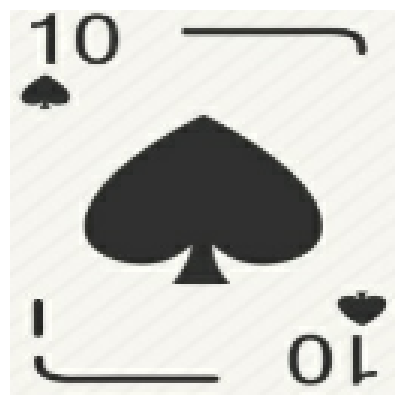

In [5]:
for images, labels in train_ds.take(1):
  plt.figure(figsize=(5, 5))

  #first image in dataset
  plt.imshow(images[0].numpy().astype("uint8"))

  plt.axis("off")

  plt.show()

In [6]:
class_names = train_ds.class_names
class_num = len(class_names)

print(class_names)
print(class_num)

['ace of clubs', 'ace of diamonds', 'ace of hearts', 'ace of spades', 'eight of clubs', 'eight of diamonds', 'eight of hearts', 'eight of spades', 'five of clubs', 'five of diamonds', 'five of hearts', 'five of spades', 'four of clubs', 'four of diamonds', 'four of hearts', 'four of spades', 'jack of clubs', 'jack of diamonds', 'jack of hearts', 'jack of spades', 'joker', 'king of clubs', 'king of diamonds', 'king of hearts', 'king of spades', 'nine of clubs', 'nine of diamonds', 'nine of hearts', 'nine of spades', 'queen of clubs', 'queen of diamonds', 'queen of hearts', 'queen of spades', 'seven of clubs', 'seven of diamonds', 'seven of hearts', 'seven of spades', 'six of clubs', 'six of diamonds', 'six of hearts', 'six of spades', 'ten of clubs', 'ten of diamonds', 'ten of hearts', 'ten of spades', 'three of clubs', 'three of diamonds', 'three of hearts', 'three of spades', 'two of clubs', 'two of diamonds', 'two of hearts', 'two of spades']
53


In [35]:
X_array = []
y_array = []

#taking only 10 since running a large amount slowed thing down a lot
for images, labels in train_ds.take(100):
  images_con = images.numpy()

  #flatten out for standard scaler
  images_con = images_con.reshape(images.shape[0], -1)

  labels_con = labels.numpy()

  X_array.append(images_con)
  y_array.append(labels_con)

X_train = np.concatenate(X_array)
y_train = np.concatenate(y_array)

In [36]:
X_train.shape
y_train.shape

(3200,)

In [37]:
X_array = []
y_array = []

for images, labels in test_ds.take(100):
  images_con = images.numpy()

  images_con = images_con.reshape(images.shape[0], -1)

  labels_con = labels.numpy()

  X_array.append(images_con)
  y_array.append(labels_con)

X_test = np.concatenate(X_array)
y_test = np.concatenate(y_array)

In [38]:
X_test.shape
y_test.shape

(265,)

In [39]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [40]:
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train_scaled,y_train)
y_pred = svm_model.predict(X_test_scaled)

In [41]:
print(y_pred)

[19 36 36 18 51  5 31  8 14 19 12 24 35  3  5 12 40 46 20 26 34 31  0 15
 35 14  2 41  9 44 28 14 18  1 17  9  5 36 16 45 14 20 17 19 41  5  2 48
 16  1 42  4 14 30 10 30 33 11 18 26  3 14 19 38 12 29  5 29 31 12 48 46
 40 29 11  3  2 49 44 19 21  4 14 35  5  0  5 28 38 18 24  2 51  7 37 40
  2 21 46  2  4  9  2 51 19 18 25 30 26  7 38  6 12 29 19 51 28 18 20 29
 40 12 21 51 51 14  0 37 38 16 18 40 21 20 19 16 51 21 41 16 20 49 28 12
 14 51 33 38 14  5 10 35 18  3  5 18 14 28 42  5 15 20  0 25 39 12 23  3
  3 48 30 36 36 46 29 51  5 43  3 20 12  5  3 11 21 51 29 15  8 12 16 10
 37  3  5 30 41  4 46 19 51 32 12 51 46 30 10 41  3 20  8 43 34  4 19 49
 12 46 19 30 17 46  8 32 42  2 39  3 17 42  5 30 51  6 18 18 29 14 20 28
 14 30 12 41 18 20  1 18  3 12 52 26 25 12  3 41 31 11 15  5  4 28  4  6
 14]


In [42]:
predict_score = accuracy_score(y_test, y_pred)
print(predict_score)

0.38113207547169814


In [43]:
svm_model = SVC(kernel='linear')
svm_model.fit(X_train_scaled,y_train)
y_pred = svm_model.predict(X_test_scaled)

In [44]:
print(y_pred)

[19 36  4 11 51 38 31 11 43 16 49 22 35  3 26  9 40 46 20 26 34 21  0  5
 35 13  2 41  9 44 28  9 13  1 23  9  5 36  8 45 13 29 21  4 44  5  1 48
 16  1 43  4  5 51  7 30 33 11 17 26  3  5 19 38  5 15 34  4 31  8  0 47
 40 22  8  0  2 49 44 44 21  4 13 35 40  0 34  7 39 18 24 43 46 28 37 40
 30 21 46  2  4  9  2 52 19  7 25 46 27 43 39  6 14 30 19 50  8 18 20 29
 40 12 21 47 50 14  0 37 38 30 18 33 21 20 19 16 48 21 41  4 20 49 28  5
 13 50  4 38 14 32 10 35  5  3 14 31 13 28 42 34 12 18  0 25 38 47 14  3
  3 45 23 33 36 26 29 50  5 43  0 24 47 12  3  8 21 47 29 12 11 47 16 10
 37  3  6 32 41  4 48 21 50 29 35 49 46 17 10 41 16 51  8 43 38  8 30 52
 47 47 45 17 23 46  8 32 42  1 39  3 22 34  5 18 34  6 39 22 29 14 20 11
 14 29 26 41 12 20  2 26  3 47 52 26 25  0  3 40 31 11 15  5 33  9  4  6
 14]


In [45]:
predict_score = accuracy_score(y_test, y_pred)
print(predict_score)

0.5056603773584906
